In [4]:
import pandas as pd
data=pd.read_csv('crop_yield_polynomial_practice.csv')

In [5]:
na_values=data.isna().sum()[data.isna().sum()>0]

na_values=pd.DataFrame(na_values)
na_values=na_values.reset_index()
na_values.columns=['NAME','COUNT']
na_values['PERCENT']=(na_values['COUNT']/len(data))*100

na_values

,NAME,COUNT,PERCENT
0,soil_type,294,5.88
1,rainfall_mm,198,3.96
2,soil_ph,252,5.04
3,sunlight_hours,254,5.08
4,pest_incidence_pct,168,3.36


In [6]:
data=data.drop(columns=['farm_id','revenue_inr','harvest_grade'])

In [7]:
y=data['yield_quintal_per_ha']
x=data.drop(columns='yield_quintal_per_ha')

In [8]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [9]:
numbers=x_train.describe(include='number').columns.tolist()
catagory=x_train.describe(exclude='number').columns.tolist()

In [10]:
x_train[numbers].corrwith(y_train)

fertilizer_kg_per_ha    -0.033521
rainfall_mm             -0.008889
avg_temperature_c       -0.012285
soil_ph                  0.032536
sunlight_hours           0.230942
seed_density_per_sqm    -0.030997
farm_experience_years    0.300620
pest_incidence_pct      -0.239686
field_size_ha            0.024195
dtype: float64

array([[<Axes: title={'center': 'fertilizer_kg_per_ha'}>,
        <Axes: title={'center': 'rainfall_mm'}>,
        <Axes: title={'center': 'avg_temperature_c'}>],
       [<Axes: title={'center': 'soil_ph'}>,
        <Axes: title={'center': 'sunlight_hours'}>,
        <Axes: title={'center': 'seed_density_per_sqm'}>],
       [<Axes: title={'center': 'farm_experience_years'}>,
        <Axes: title={'center': 'pest_incidence_pct'}>,
        <Axes: title={'center': 'field_size_ha'}>]], dtype=object)

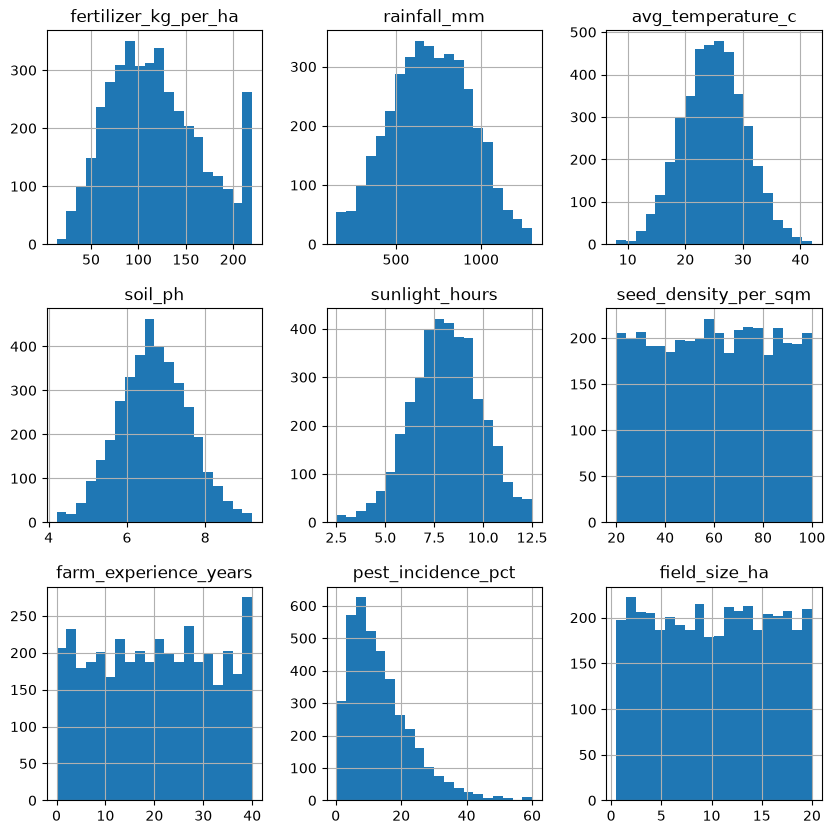

In [11]:
x_train[numbers].hist(bins=20,figsize=(10,10))

In [12]:
from sklearn.preprocessing import (OneHotEncoder,StandardScaler,PowerTransformer)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error,r2_score
from sklearn.impute import SimpleImputer
from sklearn import set_config
set_config(transform_output='pandas')
number_pipeline=Pipeline([
    ('simple imputer',SimpleImputer(strategy='median')),
    ('tranform',PowerTransformer(method='yeo-johnson')),
    ('scalar',StandardScaler())
])

catagory_pipeline=Pipeline([
    ('simple imputer',SimpleImputer(strategy='most_frequent')),
    ('OneHotEncoder',OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False))
])

preprocessor= ColumnTransformer([
     ('number_pipeline',number_pipeline,['fertilizer_kg_per_ha', 'rainfall_mm', 'avg_temperature_c', 'soil_ph',
           'sunlight_hours', 'seed_density_per_sqm', 'farm_experience_years',
           'pest_incidence_pct', 'field_size_ha']),
     ('catagory',catagory_pipeline,['region', 'soil_type', 'crop_variety', 'irrigation_type'])
],verbose_feature_names_out=False,remainder='passthrough')
   

x_train_final=preprocessor.fit_transform(x_train)
x_test_final=preprocessor.transform(x_test)


model=LinearRegression()
model.fit(x_train_final,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](20,)","[-0.03, 0.11,-0.21,...,-4.16,-8.1 ,-2.34]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](20,)","['fertilizer_kg_per_ha','rainfall_mm','avg_temperature_c',..., 'irrigation_type_Flood','irrigation_type_Rainfed', 'irrigation_type_Sprinkler']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,64.9
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,20
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(20)


In [13]:
y_pred=model.predict(x_train_final)
print('train r2',r2_score(y_train,y_pred))

train r2 0.3869759419511235


In [14]:
X_TEST_PRED=model.predict(x_test_final)
print('test r2',r2_score(y_test,X_TEST_PRED))

test r2 0.4018835490090559


For a linear regression model

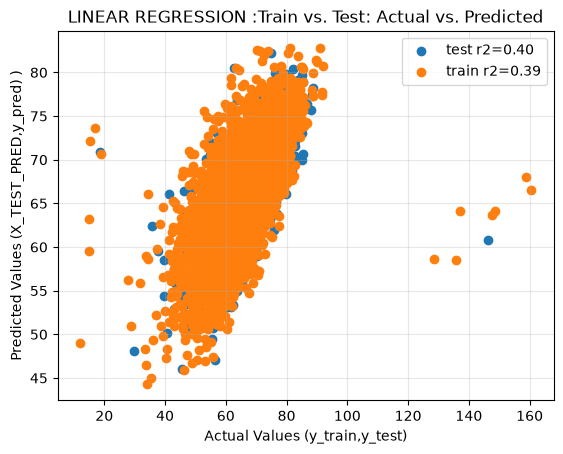

In [15]:
import matplotlib.pyplot as plt
plt.scatter(y_test,X_TEST_PRED,label= 'test r2=0.40')
plt.scatter(y_train,y_pred,label='train r2=0.39')
plt.title('LINEAR REGRESSION :Train vs. Test: Actual vs. Predicted')
plt.xlabel('Actual Values (y_train,y_test)')
plt.ylabel('Predicted Values (X_TEST_PRED,y_pred) )')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [16]:
from sklearn.preprocessing import PolynomialFeatures



In [17]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

for cols in x_train[numbers]:
    filtered=data[[cols,'yield_quintal_per_ha']].dropna()
    x=filtered[[cols]]
    y=filtered['yield_quintal_per_ha']
    linear=LinearRegression().fit(x,y).score(x,y)
    ply=make_pipeline(PolynomialFeatures(2),LinearRegression()).fit(x,y).score(x,y)
    print(cols, round(linear, 3), round(ply, 3))


fertilizer_kg_per_ha 0.001 0.138
rainfall_mm 0.0 0.067
avg_temperature_c 0.0 0.059
soil_ph 0.001 0.077
sunlight_hours 0.055 0.055
seed_density_per_sqm 0.0 0.008
farm_experience_years 0.088 0.091
pest_incidence_pct 0.059 0.059
field_size_ha 0.0 0.0


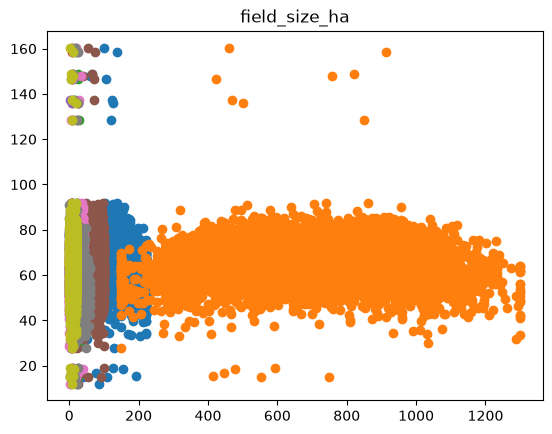

In [18]:

for cols in x_train[numbers]:
    filtered=data[[cols,'yield_quintal_per_ha']].dropna()
    plt.Figure()
    x=filtered[cols]
    y=filtered['yield_quintal_per_ha']
    plt.scatter(x,y)
    plt.title(cols)
plt.show()

In [19]:
PolynomialFeatures(2),LinearRegression().fit(x,y).score(x,y)

ValueError: Expected a 2-dimensional container but got <class 'pandas.Series'> instead. Pass a DataFrame containing a single row (i.e. single sample) or a single column (i.e. single feature) instead.

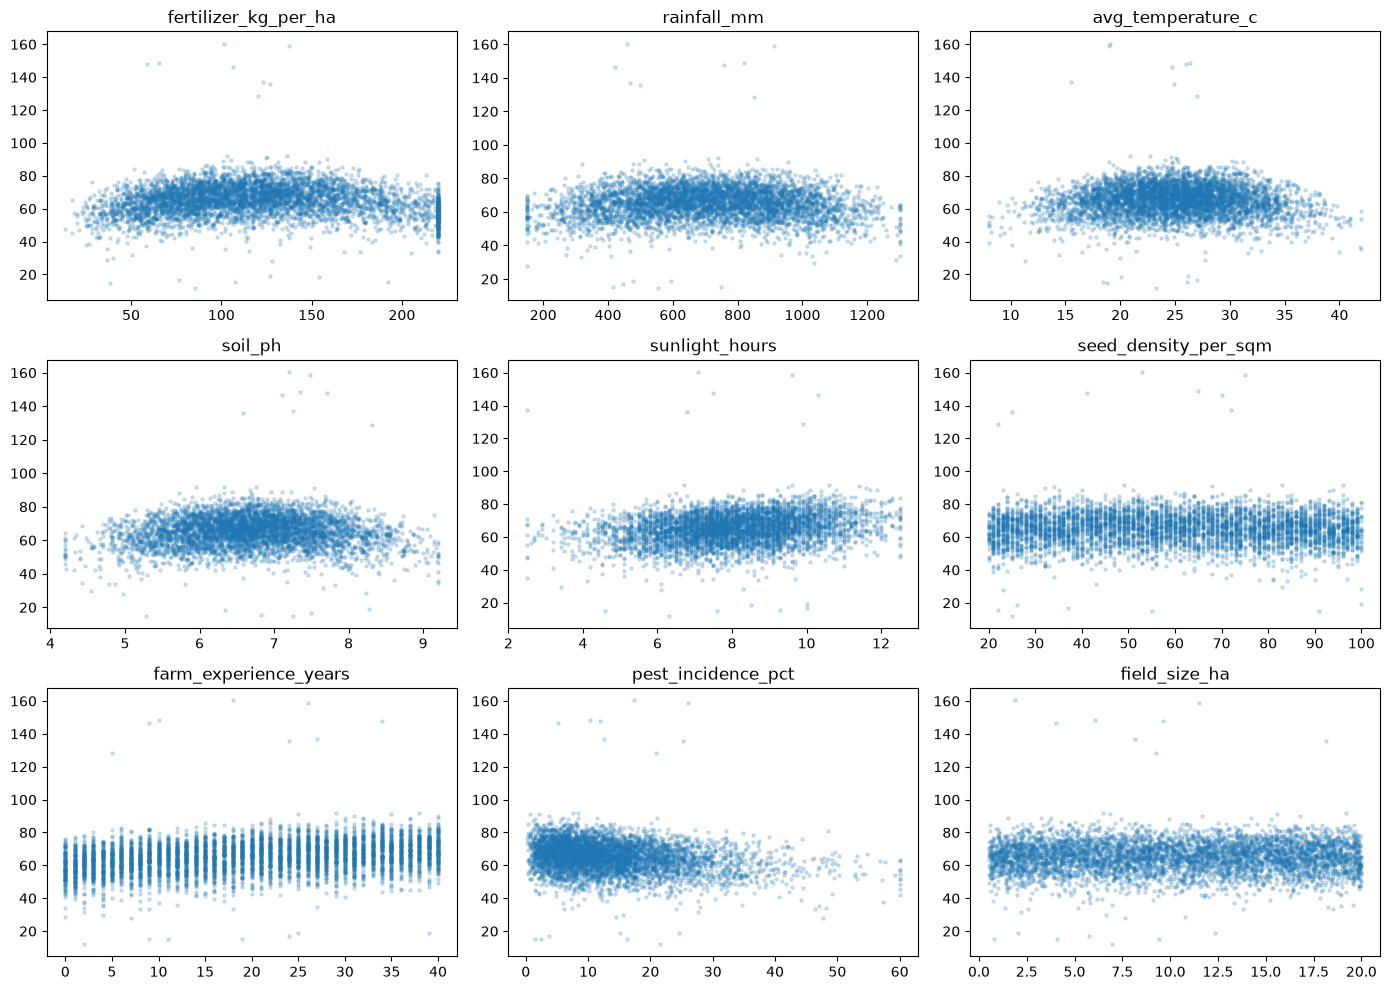

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, cols in zip(axes.ravel(), numbers):
    filtered = data[[cols, 'yield_quintal_per_ha']].dropna()
    ax.scatter(filtered[cols], filtered['yield_quintal_per_ha'], alpha=0.2, s=5)
    ax.set_title(cols)
plt.tight_layout()
plt.show()

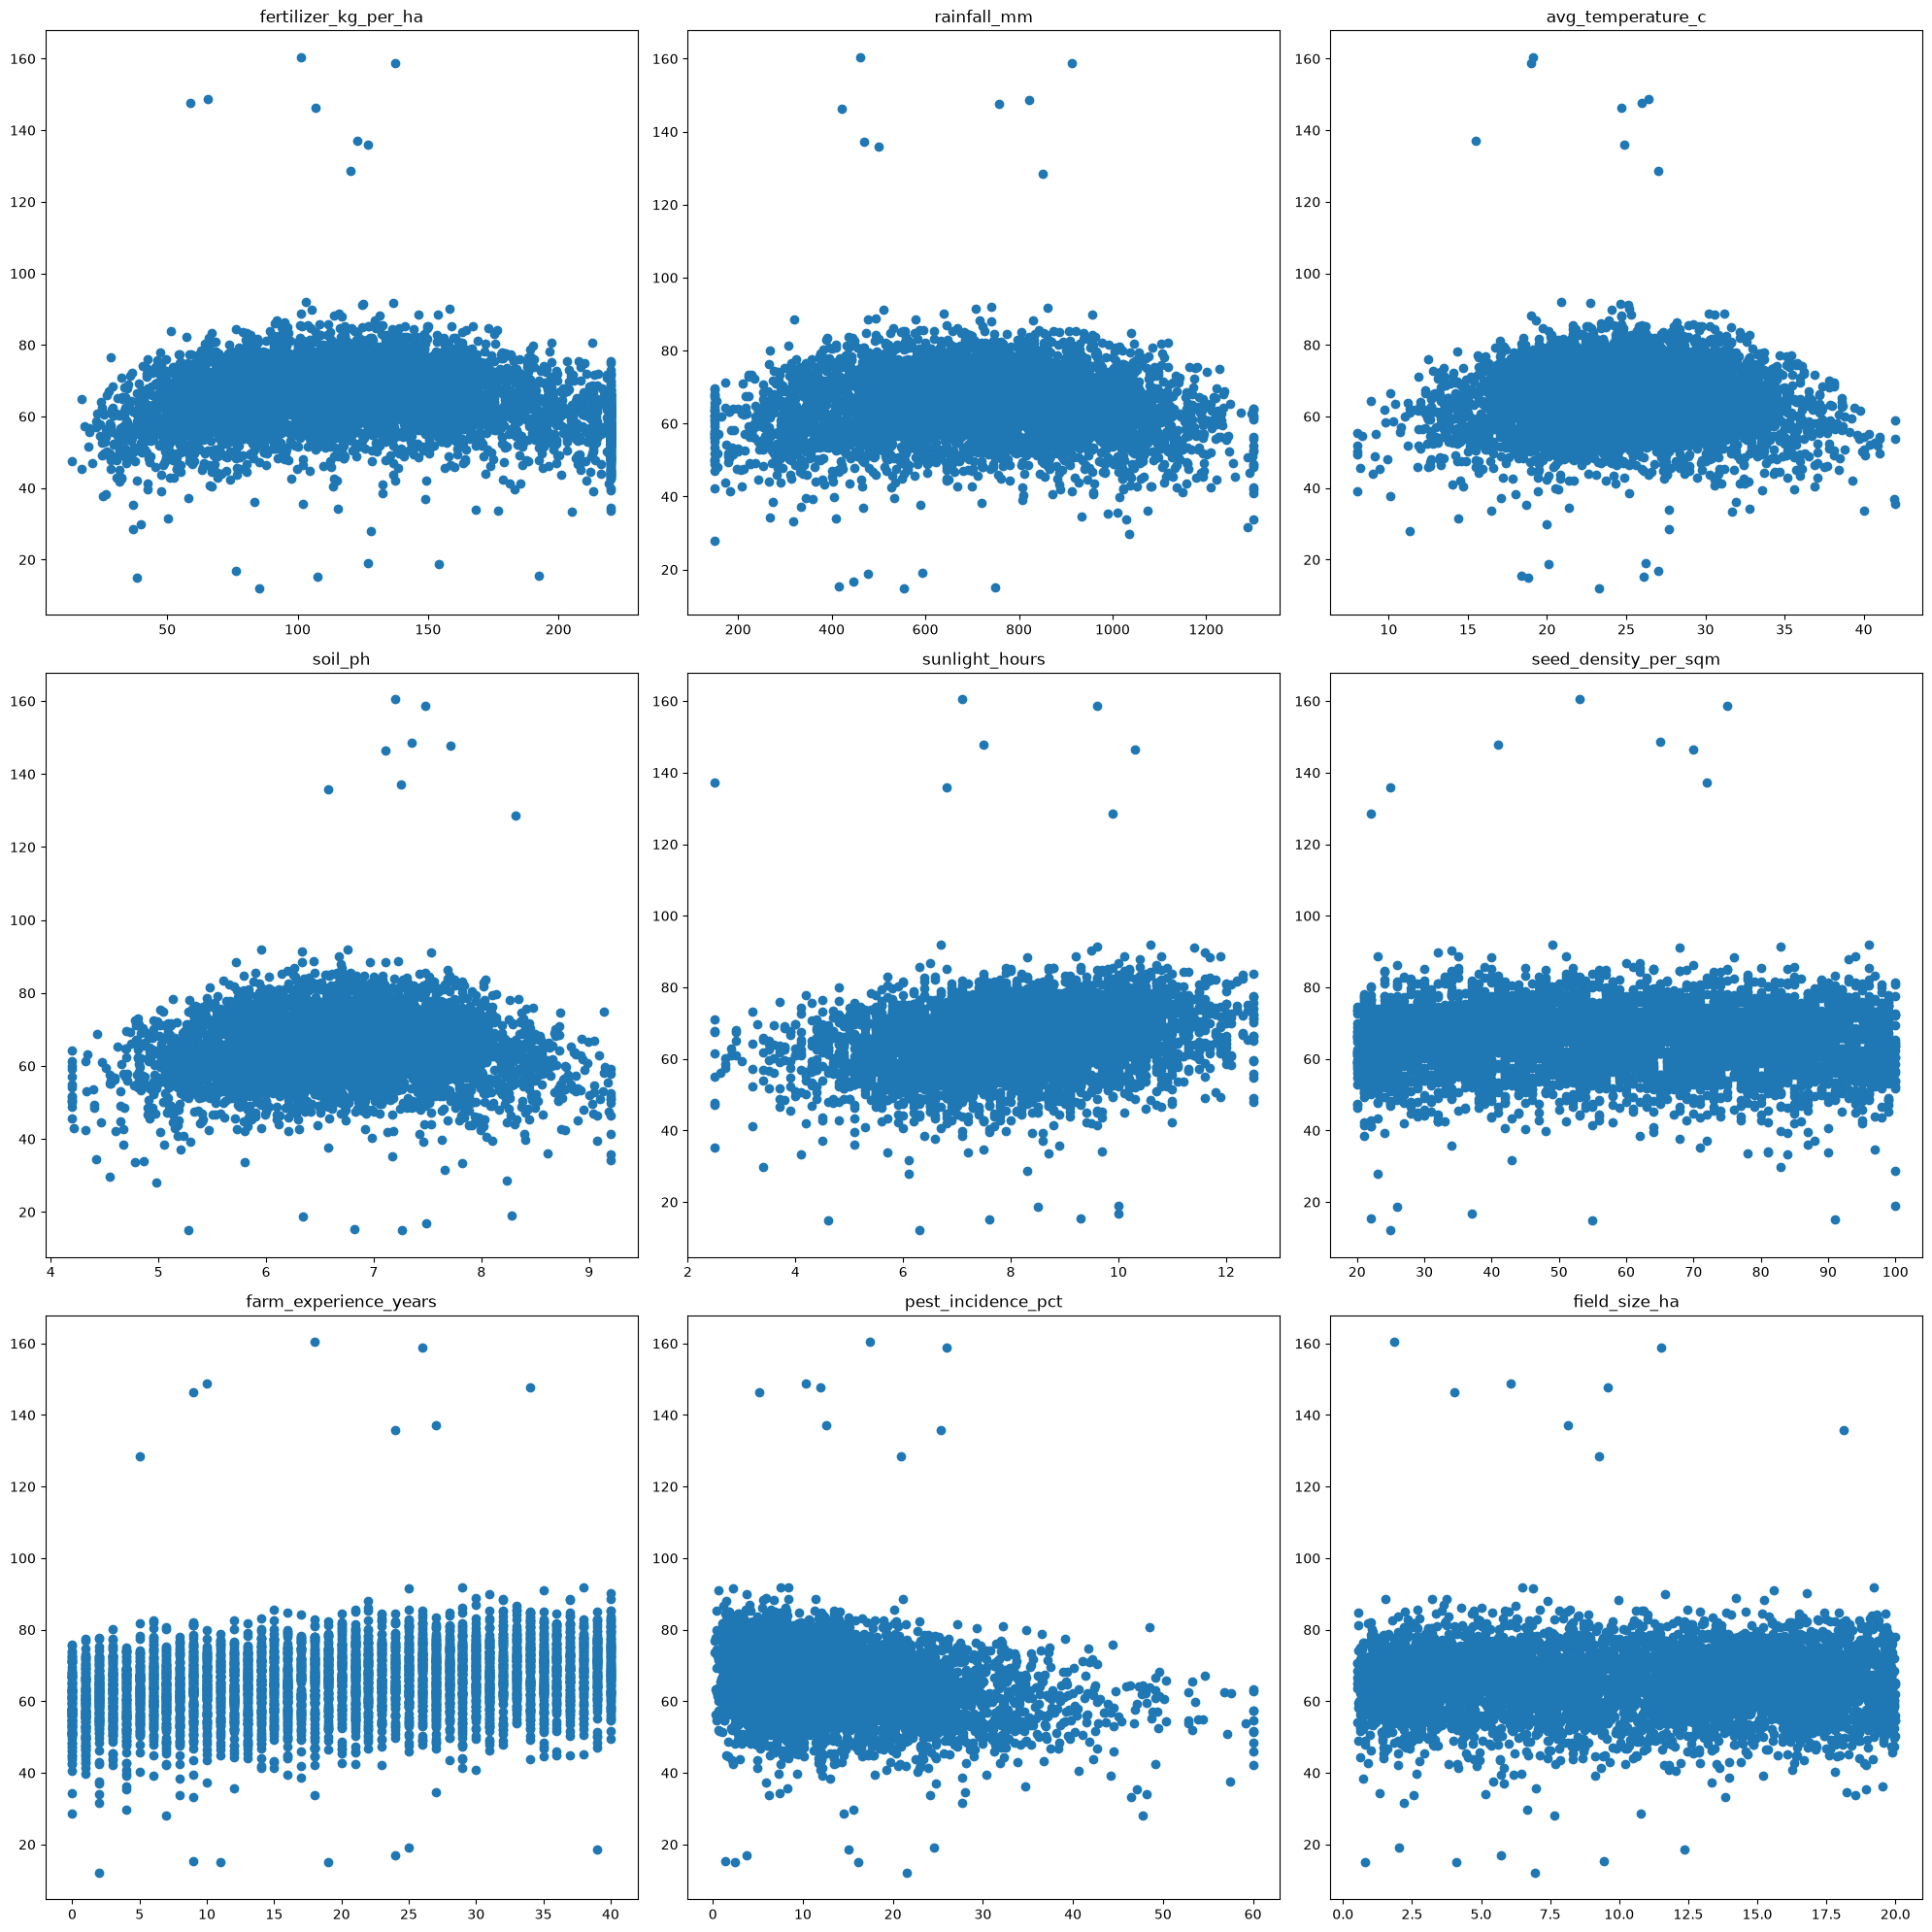

In [ ]:
fig,axes=plt.subplots(3,3,figsize=(20,20))
for ax,name in zip(axes.ravel(),numbers):
    filtered=data[[name, 'yield_quintal_per_ha']].dropna()
    x=filtered[name]
    y=filtered['yield_quintal_per_ha']
    ax.scatter(x,y)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [33]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
poly_features=[]
for cols in x_train[numbers]:
    filtered=data[[cols,'yield_quintal_per_ha']].dropna()
    x=filtered[[cols]]
    y=filtered['yield_quintal_per_ha']
    linear=LinearRegression().fit(x,y).score(x,y)
    poly=make_pipeline(PolynomialFeatures(2),LinearRegression()).fit(x,y).score(x,y)
    # print(cols, round(linear, 3), round(poly, 3))
    if round(poly, 3) > round(linear, 3):
        poly_features.append(cols)
print(poly_features)



['fertilizer_kg_per_ha', 'rainfall_mm', 'avg_temperature_c', 'soil_ph', 'seed_density_per_sqm', 'farm_experience_years']


In [34]:

from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression

linear_cols=['sunlight_hours', 'pest_incidence_pct', 'field_size_ha']

poly_pipeline = Pipeline([
    ('IMPUTE',SimpleImputer(strategy='median')),
    ('scalar',StandardScaler()),
    ('poly',PolynomialFeatures(degree=2,include_bias=False))
])

linear_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])


preprocessor=ColumnTransformer([
    ('linear_pipeline',linear_pipeline,linear_cols),
    ('poly_pipeline',poly_pipeline,poly_features),
    ('catagory_pipeline',cat_pipeline,['region', 'soil_type', 'crop_variety', 'irrigation_type'])
],verbose_feature_names_out=False,remainder='passthrough')

x_train_after_poly=preprocessor.fit_transform(x_train)
x_test_after_poly=preprocessor.transform(x_test)

model=LinearRegression()
linear_SCORE=model.fit(x_train_after_poly,y_train).score(x_train_after_poly,y_train)

In [ ]:
linear_SCORE

0.7482193821034298

In [38]:
after_poly_test_score=model.predict(x_test_after_poly)
r2=r2_score(y_test,after_poly_test_score)

In [36]:
after_poly_train_score=model.predict(x_train_after_poly)

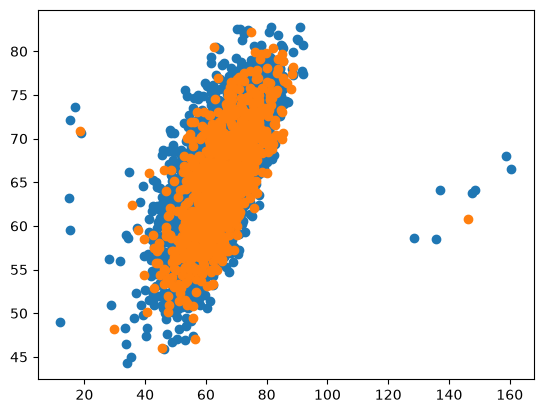

In [28]:
import matplotlib.pyplot as plt
plt.scatter(y_train,y_pred)
plt.scatter(y_test,X_TEST_PRED)


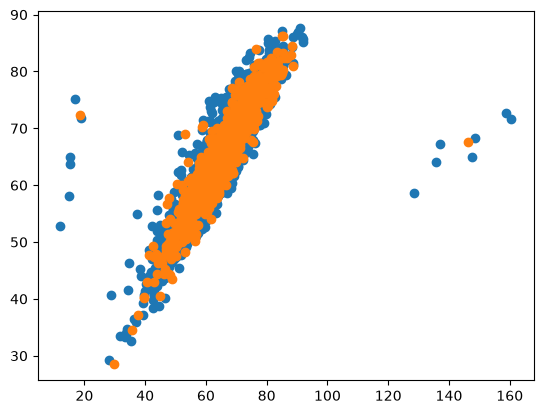

In [39]:
import matplotlib.pyplot as plt
plt.scatter(y_train,after_poly_train_score)
plt.scatter(y_test,after_poly_test_score)

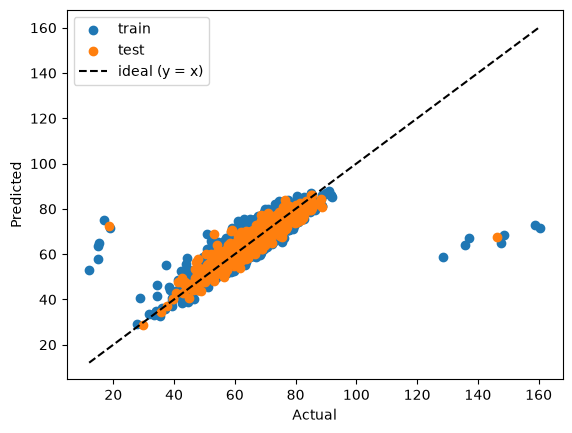

In [54]:
import numpy as np
import matplotlib.pyplot as plt

plt.scatter(y_train, after_poly_train_score, label="train")
plt.scatter(y_test, after_poly_test_score, label="test")

lims = [min(y_train.min(), y_test.min()), max(y_train.max(), y_test.max())]
plt.plot(lims, lims, "k--", label="ideal (y = x)")   # perfect prediction line

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.legend()
plt.show()

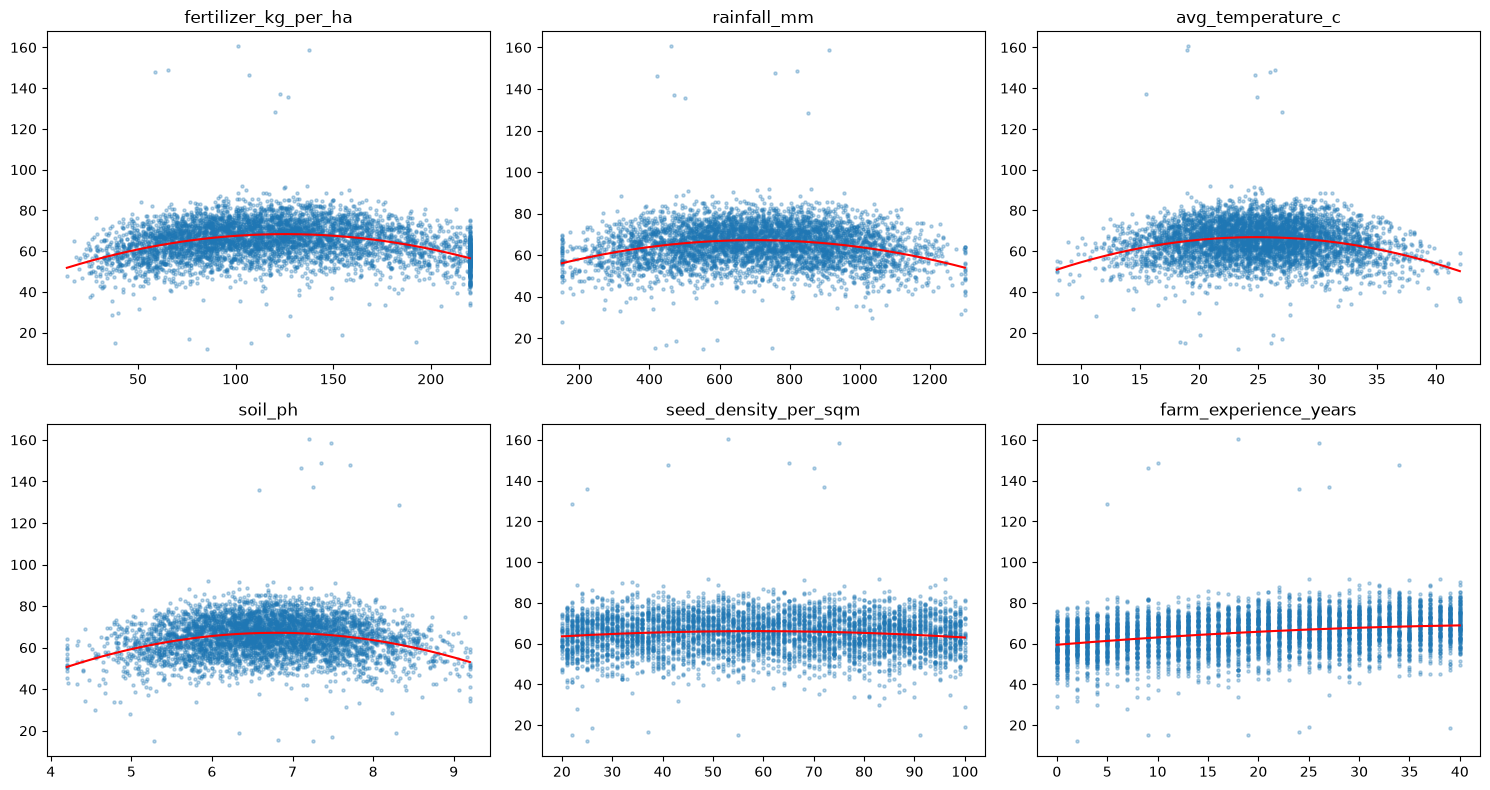

In [102]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax,cols in zip(axes.ravel(),poly_features):
    filtered= data[[cols,'yield_quintal_per_ha']].dropna()
    x=filtered[[cols]].values
    y=filtered['yield_quintal_per_ha'].values

    poly=PolynomialFeatures(degree=2)
    model = LinearRegression().fit(poly.fit_transform(x), y)

    x_line=np.linspace(x.min(), x.max(), 300).reshape(-1,1)
    y_line=model.predict(poly.transform(x_line))

    ax.scatter(x, y, alpha=0.3,s=5)            
    ax.plot(x_line, y_line, color='red')   
    ax.set_title(cols)
plt.tight_layout()    
plt.show()

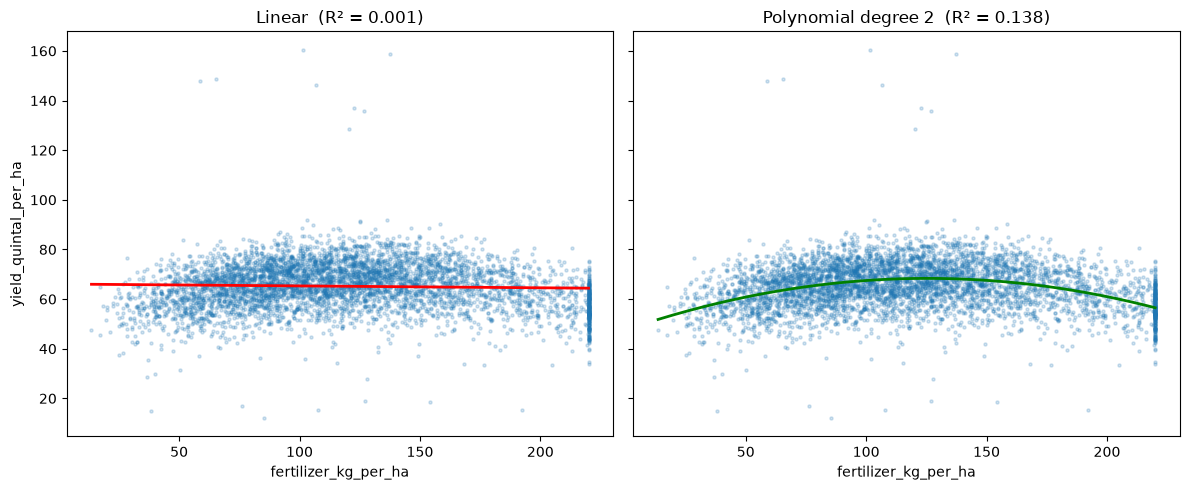

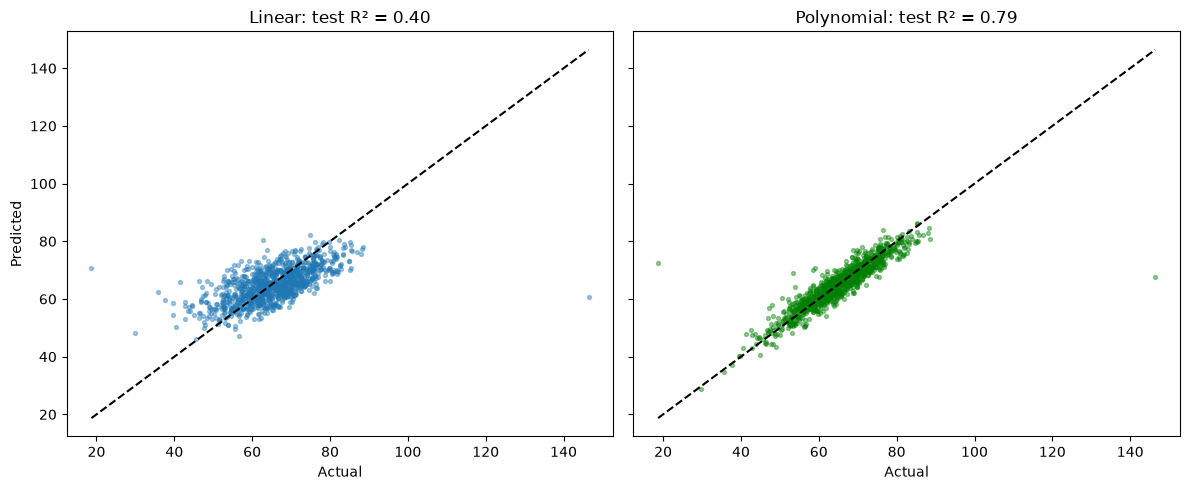

In [104]:
from sklearn.metrics import r2_score

lin_test  = r2_score(y_test, X_TEST_PRED)
poly_test = r2_score(y_test, after_poly_test_score)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

axes[0].scatter(y_test, X_TEST_PRED, alpha=0.4, s=8)
axes[0].set_title(f'Linear: test R² = {lin_test:.2f}')

axes[1].scatter(y_test, after_poly_test_score, alpha=0.4, s=8, color='green')
axes[1].set_title(f'Polynomial: test R² = {poly_test:.2f}')

lims = [y_test.min(), y_test.max()]
for ax in axes:
    ax.plot(lims, lims, 'k--')            # ideal line y = x
    ax.set_xlabel('Actual')
axes[0].set_ylabel('Predicted')

plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=200)
plt.show()